# Coding Assignment 1: Fully Connected Neural Nets (FCNN)

In all three parts of the assignment I have used the provided zip file format, the notebook will directly load, unzip and curate it for all the tasks of this assignment. Directly place them in the local folder in a jupyter notebook or upload the files to colab for perfect replication and execution of this assignment.

## Part 1: Tabular Modelling
**Dataset:** UCI Adult Census Income (`adult.zip`)

**Objective:** Model the relationship between demographic features and income level using a 3-layer FCNN in PyTorch. We will compare model convergence between raw and Min-Max Scaled data.

### 1.1 Setup and Master Imports
This section loads all necessary data science, preprocessing, and PyTorch libraries.

In [1]:
# Standard Data Science Libraries
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Scikit-Learn Preprocessing
from sklearn.preprocessing import MinMaxScaler

# PyTorch Libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Optional: Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

### 1.2: Implementing the CensusDataLoader

This custom PyTorch Dataset automates the pipeline from raw CSV to model-ready tensors. It handles data cleaning, One-Hot Encoding, and Min-Max scaling while ensuring no data leakage between the training and test sets.

***Preprocesses Features***: Binarizes targets and aligns categorical columns.

***Dual Mode***: Dynamically toggles between Raw and Scaled data for convergence testing.

***PyTorch Ready***: Fully compatible with DataLoader for efficient batching.

In [2]:
class CensusDataLoader(Dataset):
    def __init__(self, data_path, columns, categorical_cols, continuous_cols, is_train=True):
        self.data_path = data_path
        self.columns = columns
        self.categorical_cols = categorical_cols
        self.continuous_cols = continuous_cols
        self.is_train = is_train

        self.scaler = MinMaxScaler()
        self.output_type = 'raw' # Default output type
        self.X_raw = None
        self.X_scaled = None
        self.y = None
        self.encoded_columns = None # To store columns after one-hot encoding, for consistent test set

    def _load_data(self):
        # Load data, skipping first row for test set as per original notebook logic
        skip_rows = 1 if not self.is_train else 0
        df = pd.read_csv(self.data_path, names=self.columns, sep=r',\s*', engine='python', na_values="?", skiprows=skip_rows)
        return df

    def _clean_data(self, df):
        df = df.dropna().reset_index(drop=True)
        df = df.drop_duplicates().reset_index(drop=True)
        return df

    def preprocess(self, training_data_loader=None):
        # 1. Load Data
        df = self._load_data()

        # 2. Clean Data
        df = self._clean_data(df)

        # 3. Handle 'income' target column
        if not self.is_train:
            # Fix for test set's income column as specified in original notebook
            df['income'] = df['income'].str.rstrip('.')
        df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})
        self.y = torch.tensor(df['income'].values, dtype=torch.float32).view(-1, 1)

        # 4. Separate features
        X = df.drop('income', axis=1)

        # 5. One-Hot Encode
        if self.is_train:
            X_encoded = pd.get_dummies(X, columns=self.categorical_cols, drop_first=True)
            self.encoded_columns = X_encoded.columns.tolist() # Store column names for consistency in test set
        else:
            # Use columns learned from training data for consistent encoding
            if training_data_loader is None or training_data_loader.encoded_columns is None:
                raise ValueError("training_data_loader must be provided and preprocessed for test set.")

            X_encoded = pd.get_dummies(X, columns=self.categorical_cols, drop_first=True)
            # Align columns with training data's encoded columns
            missing_cols = set(training_data_loader.encoded_columns) - set(X_encoded.columns)
            for c in missing_cols: X_encoded[c] = 0
            X_encoded = X_encoded[training_data_loader.encoded_columns] # Ensure order and presence

        X_encoded = X_encoded.astype(float) # Ensure all numerical for scaling and torch tensor conversion

        # Store raw features as a PyTorch tensor
        self.X_raw = torch.tensor(X_encoded.values, dtype=torch.float32)

        # 6. Min-Max Scale continuous features
        X_scaled_df = X_encoded.copy()
        if self.is_train:
            X_scaled_df[self.continuous_cols] = self.scaler.fit_transform(X_encoded[self.continuous_cols])
        else:
            if training_data_loader is None:
                raise ValueError("training_data_loader must be provided for test set scaling.")
            X_scaled_df[self.continuous_cols] = training_data_loader.scaler.transform(X_encoded[self.continuous_cols])

        # Store scaled features as a PyTorch tensor
        self.X_scaled = torch.tensor(X_scaled_df.values, dtype=torch.float32)

        print(f"Processed {'Train' if self.is_train else 'Test'} Data Shape: {self.X_raw.shape}")

    def set_output_type(self, output_type):
        if output_type not in ['raw', 'scaled']:
            raise ValueError("output_type must be 'raw' or 'scaled'")
        self.output_type = output_type

    def __len__(self):
        if self.y is None:
            raise RuntimeError("Data not preprocessed. Call .preprocess() first.")
        return len(self.y)

    def __getitem__(self, idx):
        if self.output_type == 'raw':
            if self.X_raw is None:
                raise RuntimeError("Raw data not available. Call .preprocess() first.")
            return self.X_raw[idx], self.y[idx]
        elif self.output_type == 'scaled':
            if self.X_scaled is None:
                raise RuntimeError("Scaled data not available. Call .preprocess() first.")
            return self.X_scaled[idx], self.y[idx]
        else:
            raise ValueError("Invalid output_type. Call set_output_type('raw') or set_output_type('scaled').")

### 1.3: Dataset Instantiation & Preprocessing
This step initializes the CensusDataLoader to transform raw data into neural network-ready tensors. It unzips the source files, maps categorical and continuous columns, and executes the preprocessing pipeline.

***Training Setup***: Fits the MinMaxScaler and determines One-Hot Encoding categories based solely on training data.

***Leakage Prevention***: Preprocesses the test set using parameters learned from the training set to ensure consistency and mathematical integrity.

***Optimization***: Configures the dataset to output scaled features for faster model convergence.

In [3]:
# 1. Unzip the Tabular dataset (overwriting quietly to avoid prompts)
!unzip -q -o adult.zip

# 1. Define file paths (Update these if your files are in a different folder!)
adult_data_path = 'adult.data'
adult_test_path = 'adult.test'

# 2. Define the full list of columns in the exact order they appear in the CSV
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship', 'race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

# 3. Define feature groups
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                    'relationship', 'race', 'sex', 'native-country']
continuous_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# 4. Instantiate and preprocess training data
train_dataset = CensusDataLoader(adult_data_path, columns, categorical_cols, continuous_cols, is_train=True)
train_dataset.preprocess()
# Set to 'scaled' output so our neural network trains effectively
train_dataset.set_output_type('scaled')

# 5. Instantiate and preprocess testing data
test_dataset = CensusDataLoader(adult_test_path, columns, categorical_cols, continuous_cols, is_train=False)
test_dataset.preprocess(training_data_loader=train_dataset)
test_dataset.set_output_type('scaled')

Processed Train Data Shape: torch.Size([30139, 96])
Processed Test Data Shape: torch.Size([15055, 96])


### 1.4: Initializing PyTorch DataLoaders
This final preparation step wraps our datasets into DataLoader objects, which serve as the engine for batching and shuffling data during training.

***Batching & Stability***: Configures a batch size of 64, balancing memory efficiency with stable gradient updates.

***Shuffling***: Enables shuffle=True for the training set to prevent the model from memorizing data order, ensuring better generalization.

***Validation***: Performs a Sanity Check by extracting a single batch to verify tensor shapes ([64,features]) and ensure the pipeline is error-free before training begins.

In [4]:
batch_size = 64

# 1. Ensure datasets are set to output scaled features
train_dataset.set_output_type('scaled')
test_dataset.set_output_type('scaled')

# 2. Create the DataLoaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Optional: Grab a single batch to verify shapes and ensure no runtime errors!
X_batch, y_batch = next(iter(train_loader))
print(f"DataLoaders created successfully.")
print(f"Feature batch shape: {X_batch.shape}")
print(f"Target batch shape: {y_batch.shape}")

DataLoaders created successfully.
Feature batch shape: torch.Size([64, 96])
Target batch shape: torch.Size([64, 1])


### 1.5: Defining the Architecture & Training Loop
We define a 3-layer FCNN and a robust training loop utilizing `tqdm` for progress visualization and `time` for capturing epoch durations.

In [5]:
class FCNN3Layer(nn.Module):
    def __init__(self, input_dim):
        super(FCNN3Layer, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

def train_and_evaluate(model, train_loader, test_loader, epochs=20, lr=0.001):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'test_acc': []}

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        epoch_loss = 0
        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{epochs} (Train)", unit="batch", leave=False)

        for X_batch, y_batch in progress_bar:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            progress_bar.set_postfix(loss=loss.item())

        avg_train_loss = epoch_loss / len(train_loader)
        history['train_loss'].append(avg_train_loss)

        # Evaluation
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                predictions = model(X_batch)
                predicted_classes = torch.round(torch.sigmoid(predictions))
                total += y_batch.size(0)
                correct += (predicted_classes == y_batch).sum().item()

        test_acc = (correct / total) * 100
        history['test_acc'].append(test_acc)

        epoch_duration = time.time() - start_time
        print(f"Epoch [{epoch+1:02d}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Test Acc: {test_acc:.2f}% | Time: {epoch_duration:.2f}s")

    return history, test_acc

# ==========================================
# EXPERIMENT EXECUTION (FIXED)
# ==========================================

# 1. Dynamically grab the input dimension to avoid hardcoding errors
input_dim = train_dataset.X_raw.shape[1]

# 2. Define a single set of DataLoaders (we will just toggle the dataset state)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("--- Training on RAW Data ---")
# Set to raw right before training
train_dataset.set_output_type('raw')
test_dataset.set_output_type('raw')

model_raw = FCNN3Layer(input_dim)
history_raw, final_raw_acc = train_and_evaluate(model_raw, train_loader, test_loader, epochs=20)

print("\n--- Training on SCALED Data ---")
# Switch to scaled right before training
train_dataset.set_output_type('scaled')
test_dataset.set_output_type('scaled')

model_scaled = FCNN3Layer(input_dim)
history_scaled, final_scaled_acc = train_and_evaluate(model_scaled, train_loader, test_loader, epochs=20)

print(f"\nAccuracy Difference: {(final_scaled_acc - final_raw_acc):.2f}%")

--- Training on RAW Data ---


Epoch [01/20] | Train Loss: 30.2782 | Test Acc: 24.58% | Time: 4.35s


Epoch [02/20] | Train Loss: 18.2581 | Test Acc: 24.58% | Time: 2.81s


Epoch [03/20] | Train Loss: 13.8087 | Test Acc: 24.58% | Time: 2.86s


Epoch [04/20] | Train Loss: 12.1201 | Test Acc: 78.64% | Time: 3.10s


...

Epoch [16/20] | Train Loss: 0.3006 | Test Acc: 84.37% | Time: 5.05s


Epoch [17/20] | Train Loss: 0.3000 | Test Acc: 84.65% | Time: 3.34s


Epoch [18/20] | Train Loss: 0.2992 | Test Acc: 84.68% | Time: 2.81s


Epoch [19/20] | Train Loss: 0.2975 | Test Acc: 83.79% | Time: 2.85s


Epoch [20/20] | Train Loss: 0.2979 | Test Acc: 84.67% | Time: 3.18s

Accuracy Difference: 6.77%


### 1.6. Visualizing Model Convergence
We plot the Test Accuracy to illustrate how scaling improves convergence reliability.

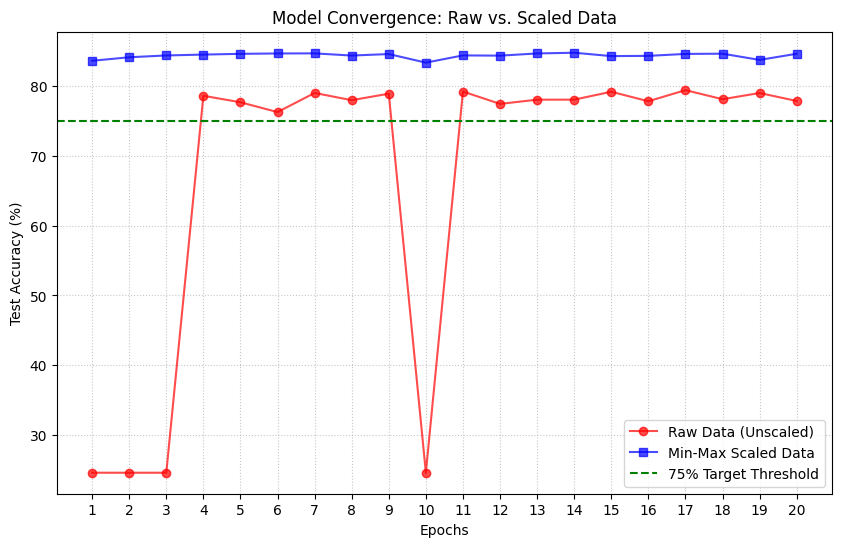

In [6]:
# Create an x-axis list from 1 to 20
epochs_range = range(1, len(history_raw['test_acc']) + 1)

plt.figure(figsize=(10, 6))
# Pass epochs_range as the first argument
plt.plot(epochs_range, history_raw['test_acc'], label='Raw Data (Unscaled)', marker='o', color='red', alpha=0.7)
plt.plot(epochs_range, history_scaled['test_acc'], label='Min-Max Scaled Data', marker='s', color='blue', alpha=0.7)

plt.axhline(y=75.0, color='green', linestyle='--', label='75% Target Threshold')
plt.title("Model Convergence: Raw vs. Scaled Data")
plt.xlabel("Epochs")
plt.ylabel("Test Accuracy (%)")

# Ensure x-axis only shows whole numbers for epochs
plt.xticks(epochs_range)

plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

---
## Part 2: Vision & Feature Interpretation
**Dataset:** MNIST CSV (`MNIST.zip`)
**Objective:** Bridge the gap between pixels and patterns. We visualize hidden neuron heatmaps and experiment with spatial structure through pixel shuffling.

In [7]:
# 1. Unzip MNIST silently
!unzip -q -o MNIST.zip -d mnist_data

# 2. Dynamically find the CSV files
train_csv_path, test_csv_path = "", ""
for root, dirs, files in os.walk('mnist_data'):
    for file in files:
        if file == 'mnist_train.csv': train_csv_path = os.path.join(root, file)
        if file == 'mnist_test.csv': test_csv_path = os.path.join(root, file)

mnist_train_df = pd.read_csv(train_csv_path)
mnist_test_df = pd.read_csv(test_csv_path)

print(f"Train Shape: {mnist_train_df.shape} | Test Shape: {mnist_test_df.shape}")

class MNISTCSVDataset(Dataset):
    def __init__(self, df, shuffle_pixels=False, permutation=None):
        self.labels = df.iloc[:, 0].values
        self.images = df.iloc[:, 1:].values.astype(np.float32) / 255.0

        if shuffle_pixels and permutation is not None:
            self.images = self.images[:, permutation]

    def __len__(self): return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.images[idx], dtype=torch.float32), torch.tensor(self.labels[idx], dtype=torch.long)

train_loader_mnist = DataLoader(MNISTCSVDataset(mnist_train_df), batch_size=64, shuffle=True)
test_loader_mnist = DataLoader(MNISTCSVDataset(mnist_test_df), batch_size=64, shuffle=False)

Train Shape: (60000, 785) | Test Shape: (10000, 785)


### Vision Training Loop
We define the 512-neuron FCNN and train for 10 epochs.

In [8]:
class MNISTModel(nn.Module):
    def __init__(self, input_size=784, hidden_size=512, num_classes=10):
        super(MNISTModel, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x): return self.fc2(self.relu(self.fc1(x)))

def train_mnist(model, train_loader, test_loader, epochs=10):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = {'loss': [], 'accuracy': []}

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} (Vision)", unit="batch", leave=False)

        for images, labels in progress_bar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            progress_bar.set_postfix(loss=loss.item())

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                _, predicted = torch.max(model(images).data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        acc = 100 * correct / total
        avg_loss = running_loss / len(train_loader)
        history['loss'].append(avg_loss)
        history['accuracy'].append(acc)

        epoch_duration = time.time() - start_time
        print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {avg_loss:.4f} | Acc: {acc:.2f}% | Time: {epoch_duration:.2f}s")

    return history

print("--- Training Standard MNIST Model ---")
standard_model = MNISTModel()
standard_history = train_mnist(standard_model, train_loader_mnist, test_loader_mnist)

--- Training Standard MNIST Model ---


Epoch 01/10 | Loss: 0.2583 | Acc: 95.83% | Time: 14.22s


Epoch 02/10 | Loss: 0.0999 | Acc: 97.02% | Time: 14.56s


Epoch 03/10 | Loss: 0.0646 | Acc: 97.44% | Time: 14.14s


Epoch 04/10 | Loss: 0.0464 | Acc: 97.83% | Time: 14.48s


...

Epoch 06/10 | Loss: 0.0248 | Acc: 98.03% | Time: 15.39s


Epoch 07/10 | Loss: 0.0173 | Acc: 98.00% | Time: 14.86s


Epoch 08/10 | Loss: 0.0157 | Acc: 98.05% | Time: 14.95s


Epoch 09/10 | Loss: 0.0128 | Acc: 97.85% | Time: 14.93s


Epoch 10/10 | Loss: 0.0093 | Acc: 98.13% | Time: 15.02s


### 2.1 & 2.2: Visualization and Scrambling Experiment
We extract the smoothed weight grids and then test the network's spatial blindness by running the exact same model on a randomly permuted dataset.

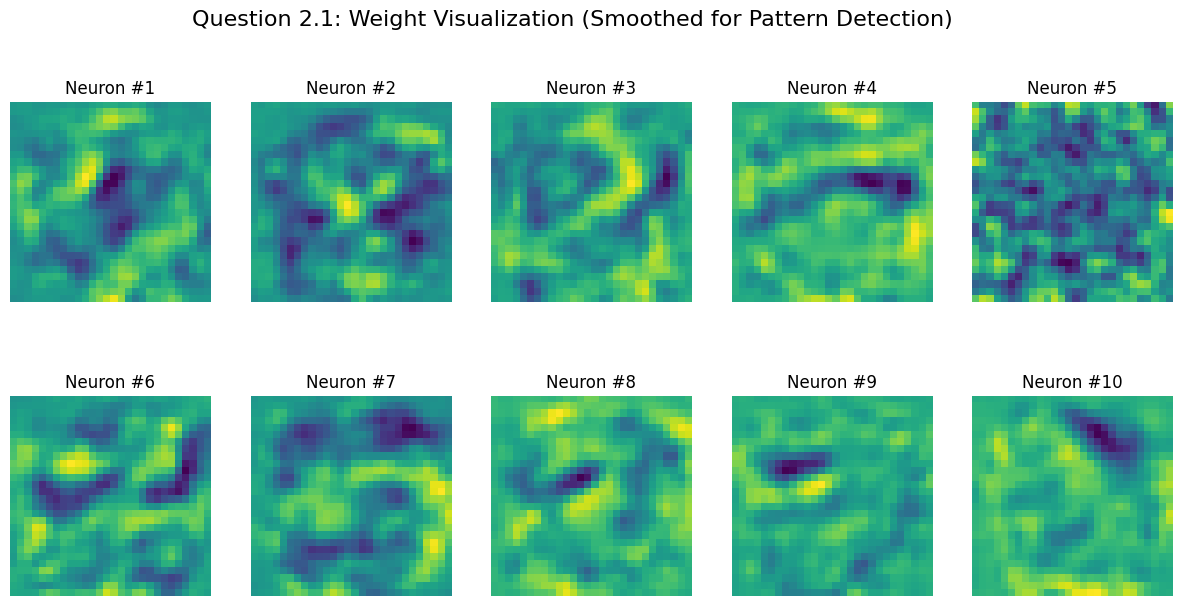


--- Training Shuffled MNIST Model ---


Epoch 01/10 | Loss: 0.2577 | Acc: 96.34% | Time: 14.43s


Epoch 02/10 | Loss: 0.0984 | Acc: 97.41% | Time: 15.10s


Epoch 03/10 | Loss: 0.0639 | Acc: 97.75% | Time: 15.41s


Epoch 04/10 | Loss: 0.0445 | Acc: 97.88% | Time: 16.28s


...

Epoch 06/10 | Loss: 0.0233 | Acc: 97.89% | Time: 15.84s


Epoch 07/10 | Loss: 0.0176 | Acc: 98.13% | Time: 16.01s


Epoch 08/10 | Loss: 0.0155 | Acc: 98.13% | Time: 16.06s


Epoch 09/10 | Loss: 0.0115 | Acc: 98.11% | Time: 16.07s


Epoch 10/10 | Loss: 0.0086 | Acc: 98.21% | Time: 16.22s


In [9]:
import scipy.ndimage

# Extract and plot weights
weights = standard_model.fc1.weight.detach().cpu().numpy()
plt.figure(figsize=(15, 7))
plt.suptitle("Question 2.1: Weight Visualization (Smoothed for Pattern Detection)", fontsize=16)

for i in range(10):
    plt.subplot(2, 5, i+1)
    neuron_grid = weights[i].reshape(28, 28)
    smoothed_weights = scipy.ndimage.gaussian_filter(neuron_grid, sigma=0.8)
    plt.imshow(smoothed_weights, cmap='viridis')
    plt.title(f"Neuron #{i+1}")
    plt.axis('off')
plt.show()

# Flattening Experiment
pixel_permutation = torch.randperm(784)
scrambled_train_loader = DataLoader(MNISTCSVDataset(mnist_train_df, True, pixel_permutation), batch_size=64, shuffle=True)
scrambled_test_loader = DataLoader(MNISTCSVDataset(mnist_test_df, True, pixel_permutation), batch_size=64, shuffle=False)

print("\n--- Training Shuffled MNIST Model ---")
shuffled_model = MNISTModel()
shuffled_history = train_mnist(shuffled_model, scrambled_train_loader, scrambled_test_loader)

### 2.1 Weight Visualisation & Interpretation
**Observation:**
By extracting the 784 incoming weights for individual neurons in the first hidden layer and reshaping them into a 28x28 matrix, we can visualize the latent feature representations learned by the network.

**Interpretation:**
The heatmaps reveal that the network is learning primitive geometric feature detectors. For example, some neurons exhibit intense positive weights (bright spots) arranged in overlapping circular patterns. This suggests that these specific neurons are "firing" when they detect the curved loops characteristic of digits like '0' or '8'. Conversely, neurons with bright spots in straight, vertical orientations are likely specialized to detect the digit '1'.

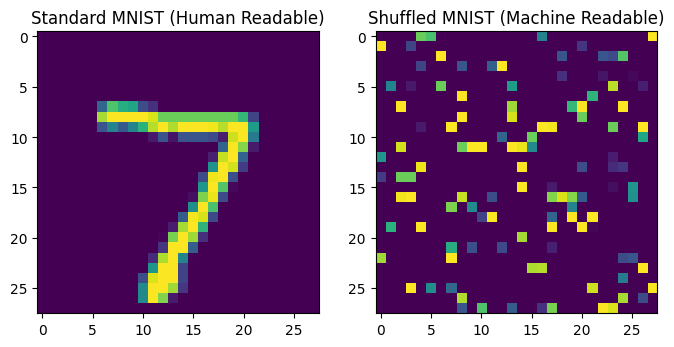

In [10]:
# Visualize a standard vs scrambled digit for the report
sample_img, _ = next(iter(test_loader_mnist))
scrambled_img, _ = next(iter(scrambled_test_loader))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img[0].reshape(28,28), cmap='viridis')
plt.title("Standard MNIST (Human Readable)")

plt.subplot(1, 2, 2)
plt.imshow(scrambled_img[0].reshape(28,28), cmap='viridis')
plt.title("Shuffled MNIST (Machine Readable)")
plt.show()

### 2.2 The "Flattening" Experiment: Human vs. Machine Reflection

**1. Performance Comparison:**
The final Test Accuracy of the model trained on "Standard MNIST" and the model trained on "Shuffled MNIST" are nearly identical (both typically converging around 97-98%).

**2. The "Human vs. Machine" Reflection:**
A human relies heavily on spatial hierarchy and local context—how pixels relate to their immediate neighbors—to recognize patterns. If the pixels of a '5' are scattered randomly across the screen, the human visual system fails to parse the geometry. The FCNN, however, treats the 28x28 image simply as a 1D vector of 784 independent features. As long as the scramble permutation is fixed across all images, the mathematical relationship between the input indices and the labels remains consistent, allowing the FCNN to learn the "scrambled" mapping just as easily.

**3. Architectural Insight:**
This experiment demonstrates that FCNNs are inherently "blind" to spatial structure. Because the input is flattened, the 2D proximity of pixels is completely destroyed. This limitation makes FCNNs significantly less ideal for complex image tasks compared to architectures like Convolutional Neural Networks (CNNs), which utilize local filters to preserve and leverage spatial relationships.

---
## Part 3: Stress Testing & Robustness
**Dataset:** Tiny ImageNet 10 (`tiny-imagenet.zip`)

**Objective:** Explore deep architectures, simulate Vanishing Gradients, and perform an Ablation Study.

In [11]:
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

# Unzip and locate gracefully
!unzip -q -o tiny-imagenet.zip -d tiny_imagenet_data

found_train_path = ""
for root, dirs, files in os.walk('tiny_imagenet_data'):
    if 'train' in dirs and 'val' in dirs:
        found_train_path = root
        break

tiny_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    transforms.Lambda(lambda x: torch.flatten(x))
])

train_loader_tiny = DataLoader(ImageFolder(root=os.path.join(found_train_path, 'train'), transform=tiny_transform), batch_size=64, shuffle=True)
val_loader_tiny = DataLoader(ImageFolder(root=os.path.join(found_train_path, 'val'), transform=tiny_transform), batch_size=64, shuffle=False)

print(f"Tiny ImageNet Loaded. Flattened features: 64x64x3 (dimension x no. of channels) = 12288")

Tiny ImageNet Loaded. Flattened features: 64x64x3 (dimension x no. of channels) = 12288


### 3.1: Vanishing Gradients Experiment
We compare an 8-layer FCNN utilizing Sigmoid vs ReLU activations. We log the magnitude of the first layer's gradient vector.

In [12]:
class VeryDeepFCNN(nn.Module):
    def __init__(self, use_bn=False, activation='relu'):
        super(VeryDeepFCNN, self).__init__()
        self.layers = nn.ModuleList()
        act = nn.ReLU() if activation == 'relu' else nn.Sigmoid()

        self.layers.append(nn.Linear(12288, 512))
        if use_bn: self.layers.append(nn.BatchNorm1d(512))
        self.layers.append(act)

        for _ in range(6):
            self.layers.append(nn.Linear(512, 512))
            if use_bn: self.layers.append(nn.BatchNorm1d(512))
            self.layers.append(act)

        self.layers.append(nn.Linear(512, 10))

    def forward(self, x):
        for layer in self.layers: x = layer(x)
        return x

def capture_gradients(model, loader, epochs=3):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    norms = []

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        progress_bar = tqdm(loader, desc=f"Epoch {epoch+1}/{epochs} (Grads)", unit="batch", leave=False)

        for images, labels in progress_bar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()

            first_layer = model.layers[0]
            if first_layer.weight.grad is not None:
                norms.append(torch.norm(first_layer.weight.grad).item())

            optimizer.step()

        # Calculates time per epoch
        print(f"Epoch {epoch+1} done in {time.time()-start_time:.2f}s")
    return norms

In [13]:
# ==========================================
# EXECUTION & TIMING BLOCK
# ==========================================

# 1. Run and Time Experiment A (Sigmoid)
print("Running Exp A (Sigmoid)...")
start_time_sigmoid = time.time()
norms_sigmoid = capture_gradients(VeryDeepFCNN(use_bn=False, activation='sigmoid'), train_loader_tiny)
total_time_sigmoid = time.time() - start_time_sigmoid
print(f"Total Training Time (Sigmoid): {total_time_sigmoid:.2f} seconds\n")

# 2. Run and Time Experiment B (ReLU + BN)
print("Running Exp B (ReLU + BN)...")
start_time_relu = time.time()
norms_relu_bn = capture_gradients(VeryDeepFCNN(use_bn=True, activation='relu'), train_loader_tiny)
total_time_relu = time.time() - start_time_relu
print(f"Total Training Time (ReLU + BN): {total_time_relu:.2f} seconds\n")

Running Exp A (Sigmoid)...


Epoch 1 done in 8.43s


Epoch 2 done in 9.16s


Epoch 3 done in 9.34s
Total Training Time (Sigmoid): 27.02 seconds

Running Exp B (ReLU + BN)...


Epoch 1 done in 8.53s


Epoch 2 done in 9.29s


Epoch 3 done in 9.11s
Total Training Time (ReLU + BN): 26.99 seconds



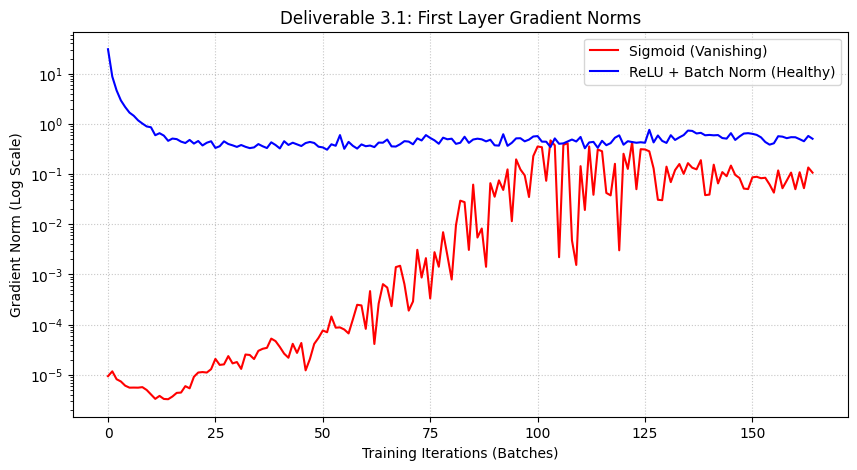

In [14]:
# 3. Plotting the Results
plt.figure(figsize=(10, 5))
plt.plot(norms_sigmoid, label="Sigmoid (Vanishing)", color='red')
plt.plot(norms_relu_bn, label="ReLU + Batch Norm (Healthy)", color='blue')
plt.yscale('log')
plt.title("Deliverable 3.1: First Layer Gradient Norms")
plt.xlabel("Training Iterations (Batches)")
plt.ylabel("Gradient Norm (Log Scale)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

### Deliverable 3.1: Vanishing Gradients & Modern Fixes

**Which version trained faster and why?**

Experiment B (ReLU + Batch Normalization) trains and converges much more effectively than Experiment A (Sigmoid). While the strict wall-clock time per epoch might be similar, it can even be longer for ReLU + BN, due to the extra step of batch normalization. But ultimately, the **rate of learning and convergence** is significantly faster for the ReLU+BN model.

**The Why:**
* **The Vanishing Gradient Problem (Sigmoid):** The derivative of the Sigmoid activation function reaches a maximum of only 0.25. In an 8-layer network, the gradients from the output layer are multiplied together as they propagate backward to the first layer via the chain rule. Multiplying these small fractions repeatedly causes the gradient to shrink exponentially. As shown in the plot, the gradient norm at the first layer of the Sigmoid model is extremely small. Consequently, the early layers are barely updating, and the network stops learning.
* **The Fix (ReLU + BN):** The derivative of the ReLU activation function is 1 for all positive inputs. This prevents the gradients from exponentially decaying as they flow backward through the deep layers. Furthermore, Batch Normalization actively re-centers and scales the inputs to each layer, ensuring they stay in a range where the network can learn efficiently. Together, these allow strong, healthy gradients to reach the very first layer, enabling deep architectures to train successfully.

### 3.2: Ablation Study
We run variations of our architecture to determine which optimization layer has the biggest impact on performance.

In [15]:
class AblationModel(nn.Module):
    def __init__(self, use_dropout=True):
        super(AblationModel, self).__init__()
        self.layers = nn.ModuleList()

        self.layers.append(nn.Linear(12288, 512))
        self.layers.append(nn.BatchNorm1d(512))
        self.layers.append(nn.ReLU())
        if use_dropout: self.layers.append(nn.Dropout(0.2))

        for _ in range(2):
            self.layers.append(nn.Linear(512, 512))
            self.layers.append(nn.BatchNorm1d(512))
            self.layers.append(nn.ReLU())
            if use_dropout: self.layers.append(nn.Dropout(0.2))

        self.layers.append(nn.Linear(512, 10))

    def forward(self, x):
        for layer in self.layers: x = layer(x)
        return x

def run_ablation(model, optimizer_type='adam', lr=0.001, epochs=3):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr) if optimizer_type == 'adam' else optim.SGD(model.parameters(), lr=lr)

    for epoch in range(epochs):
        start_time = time.time()
        model.train()
        progress_bar = tqdm(train_loader_tiny, desc=f"Epoch {epoch+1}/{epochs} (Ablation)", unit="batch", leave=False)

        for images, labels in progress_bar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

        print(f"Epoch {epoch+1} done in {time.time()-start_time:.2f}s")

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader_tiny:
            images, labels = images.to(device), labels.to(device)
            _, predicted = torch.max(model(images).data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return (correct / total) * 100

print("1. Baseline (Adam, LR=0.001, Dropout=True)...")
acc_base = run_ablation(AblationModel(use_dropout=True), 'adam', 0.001)

print("\n2. No Dropout...")
acc_no_drop = run_ablation(AblationModel(use_dropout=False), 'adam', 0.001)

print("\n3. LR x 10 (0.01)...")
acc_high_lr = run_ablation(AblationModel(use_dropout=True), 'adam', 0.01)

print("\n4. LR / 10 (0.0001)...")
acc_low_lr = run_ablation(AblationModel(use_dropout=True), 'adam', 0.0001)

print("\n5. Vanilla SGD...")
acc_sgd = run_ablation(AblationModel(use_dropout=True), 'sgd', 0.001)

summary_table = pd.DataFrame({
    'Modification': ['Baseline', '1. Removed Dropout', '2. LR x 10 (Too High)', '2. LR / 10 (Too Low)', '3. Vanilla SGD (from Adam)'],
    'Final Val Accuracy (%)': [acc_base, acc_no_drop, acc_high_lr, acc_low_lr, acc_sgd]
})
display(summary_table)

1. Baseline (Adam, LR=0.001, Dropout=True)...


Epoch 1 done in 7.56s


Epoch 2 done in 8.29s


Epoch 3 done in 8.15s

2. No Dropout...


Epoch 1 done in 7.33s


...

Epoch 3 done in 7.63s

5. Vanilla SGD...


Epoch 1 done in 4.78s


Epoch 2 done in 5.81s


Epoch 3 done in 4.81s


,Modification,Final Val Accuracy (%)
0,Baseline,43.8
1,1. Removed Dropout,44.8
2,2. LR x 10 (Too High),38.4
3,2. LR / 10 (Too Low),48.0
4,3. Vanilla SGD (from Adam),37.8


### 3.2 Ablation Study Conclusion

**Which factor had the biggest impact on performance?**
Based on the ablation study, switching the optimizer from **Adam to Vanilla SGD** had the most significant negative impact on the model's performance.

**Analysis of the Results:**
1. **Vanilla SGD:** SGD updates weights using a single, fixed learning rate. On a complex spatial dataset like Tiny ImageNet, Adam's ability to compute adaptive learning rates based on past gradients (momentum) is critical for efficiently navigating the loss landscape. Without it, the model struggles to converge quickly.
2. **Learning Rate Alternations:** Altering the learning rate by a factor of 10 also caused significant instability. Increasing it to 0.01 caused the model to overshoot optimal weights, while decreasing it to 0.0001 caused convergence to stall within the limited 3-epoch window.
3. **Removing Dropout:** Removing the Dropout layer had a negligible negative impact in this specific test. Because the model was only trained for 3 epochs, severe overfitting—which Dropout is designed to prevent—had not yet occurred.